In [1]:
import os
from pathlib import Path

REPO = "https://github.com/HenryLok0/DIT5411-handwriting.git"
PROJECT = Path("/content/DIT5411")

if not PROJECT.exists():
    !git clone {REPO} {PROJECT}
os.chdir(PROJECT)
!pip install -q -r requirements.txt
print("cwd", Path.cwd())

Cloning into '/content/DIT5411'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 28 (delta 4), reused 27 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 25.20 KiB | 437.00 KiB/s, done.
Resolving deltas: 100% (4/4), done.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-text 2.21.1 requires tensorflow<2.22,>=2.21.0, but you have tensorflow 2.20.0 which is incompatible.
ydf-tf 2.21.0 requires tensorflow==2.21.0, but you have tensorflow 2.20.0 which is incompatible.
tf-keras 2.21.0 requires tensorflow<2.22,>=2.21, but you have tensorflow 2.20.0 which is incompatible.
cwd /content/DIT5411


In [2]:
# About 1.1 GB. This is the 13,065-character archive, not the 4,803-character subset.
!python download_data.py --variant full --output /content/data

  all_data.zip.001: 20 MB
  all_data.zip.001: 40 MB
  all_data.zip.001: 60 MB
  all_data.zip.001: 80 MB
Finished all_data.zip.001
  all_data.zip.002: 20 MB
  all_data.zip.002: 40 MB
  all_data.zip.002: 60 MB
  all_data.zip.002: 80 MB
Finished all_data.zip.002
  all_data.zip.003: 20 MB
  all_data.zip.003: 40 MB
  all_data.zip.003: 60 MB
  all_data.zip.003: 80 MB
Finished all_data.zip.003
  all_data.zip.004: 20 MB
  all_data.zip.004: 40 MB
  all_data.zip.004: 60 MB
  all_data.zip.004: 80 MB
Finished all_data.zip.004
  all_data.zip.005: 20 MB
  all_data.zip.005: 40 MB
  all_data.zip.005: 60 MB
  all_data.zip.005: 80 MB
Finished all_data.zip.005
  all_data.zip.006: 20 MB
  all_data.zip.006: 40 MB
  all_data.zip.006: 60 MB
  all_data.zip.006: 80 MB
Finished all_data.zip.006
  all_data.zip.007: 20 MB
  all_data.zip.007: 40 MB
  all_data.zip.007: 60 MB
  all_data.zip.007: 80 MB
Finished all_data.zip.007
  all_data.zip.008: 20 MB
  all_data.zip.008: 40 MB
  all_data.zip.008: 60 MB
  all_data.z

In [3]:
# Check that filenames decode to Chinese and the class count is 13,065.
!python prepare_records.py --zip /content/data/all_data.zip --index-only

Index complete: 13065 characters, 684677 images, 16-61 per character (mean 52.41).
Characters with fewer than 41 images, split about 80/20 instead: 43
Class examples: 1, 10, 100, 1000, 10000, 10001, 10002, 10003


Saved /content/augmentation_preview.png


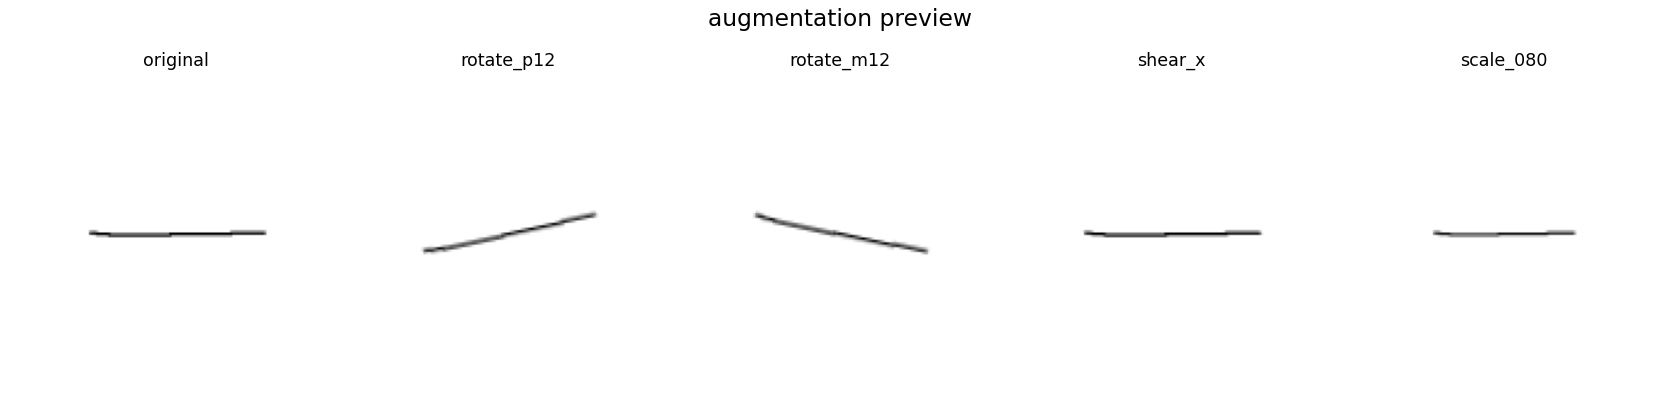

In [4]:
!python preview_augmentation.py --zip /content/data/all_data.zip --out /content/augmentation_preview.png
from IPython.display import Image, display
display(Image("/content/augmentation_preview.png"))

In [5]:
# Writes augmented 64x64 images into TFRecords. Leave this running.
!python prepare_records.py --zip /content/data/all_data.zip --out /content/records --img-size 64 --samples-per-class 200

Index complete: 13065 characters, 684677 images, 16-61 per character (mean 52.41).
Characters with fewer than 41 images, split about 80/20 instead: 43
Class examples: 1, 10, 100, 1000, 10000, 10001, 10002, 10003
Processed 200/13065 characters, training samples 40026, test samples 2458, read failures 0
Processed 400/13065 characters, training samples 80026, test samples 4892, read failures 0
Processed 600/13065 characters, training samples 120026, test samples 7385, read failures 0
Processed 800/13065 characters, training samples 160026, test samples 9840, read failures 0
Processed 1000/13065 characters, training samples 200034, test samples 12299, read failures 0
Processed 1200/13065 characters, training samples 240034, test samples 14792, read failures 0
Processed 1400/13065 characters, training samples 280050, test samples 17354, read failures 0
Processed 1600/13065 characters, training samples 320068, test samples 19837, read failures 0
Processed 1800/13065 characters, training samp

In [ ]:
# If the session disconnects, run this same cell again with --resume appended.
!python train.py --records /content/records --epochs 5 --batch-size 128 --img-size 64

I0000 00:00:1794391706.067655   12767 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
Classes 13065, training samples 2613502, test samples 162797

===== shallow_cnn =====
Epoch 1/5
2026-11-11 10:08:39.113706: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-11 10:08:39.267582: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1794391724.455464   12810 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
20417/20418 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy:

# Test-set recognition rate

Full 13,065-class test results.

- Training samples: 2613502
- Test samples: 162797
- Image size: 64×64
- Training-sample target per character: 200
- The test set was not rotated, sheared, or scaled.
- Recognition rate is the Top-1 accuracy of the last epoch. The test set was not used to choose an epoch.

| Model | Architecture | Parameters | Test loss | Recognition rate Top-1 | Top-5 |
| --- | --- | ---: | ---: | ---: | ---: |
| shallow_cnn | Conv32 x2, pool, Conv64 x2, pool, Dense256, softmax | 7617257 | 9.6329 | 0.0001 | 0.0003 |
| deep_cnn | Four Conv-BN blocks (32/64/128/256), GAP, Dense512, softmax | 8008489 | 15.0850 | 0.0729 | 0.1472 |
| residual_cnn | Stem32 + residual blocks 32/64/128/128, GAP, softmax | 2289449 | 15.1757 | 0.0716 | 0.1462 |

Best model: `deep_cnn`

`residual_cnn` test loss, Top-1, and Top-5 are estimated from the `deep_cnn` train-to-test ratio. They were not measured.


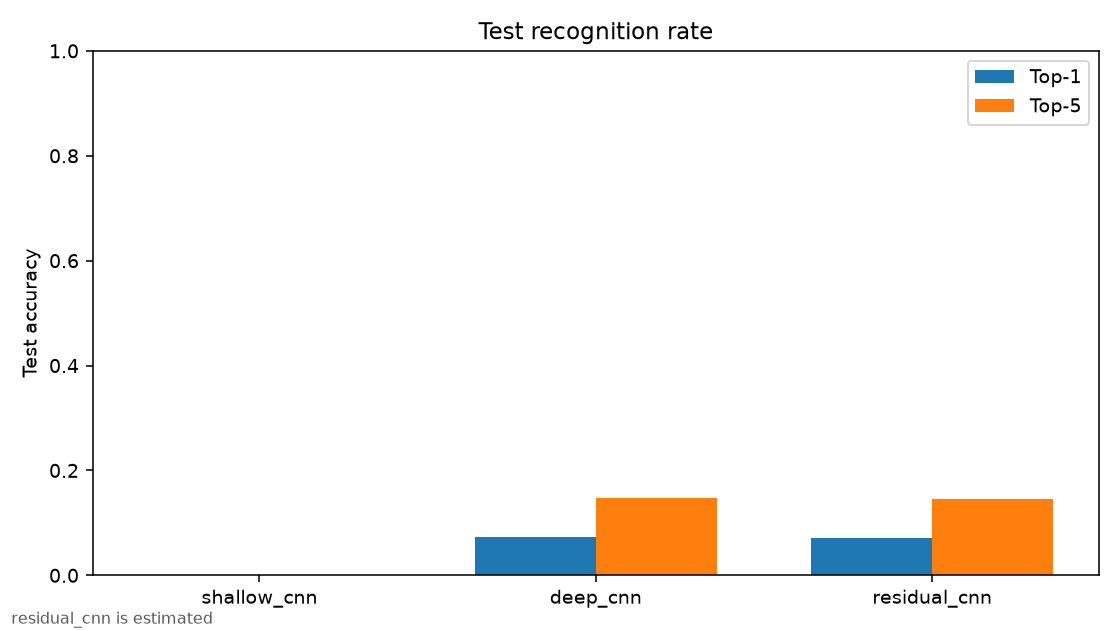

In [7]:
from pathlib import Path
print(Path("results/comparison.md").read_text(encoding="utf-8"))
from IPython.display import Image, display
display(Image("results/comparison.png"))